In [1]:
import matplotlib.pyplot as plt
import numpy as np
import openpnm as op

import porespy as ps

In [28]:
seg = np.load("../../data_new/Fine_microstructure_3/segmented_percolated.npy")
im = (seg==3).astype(np.uint8)
snow_output = ps.networks.snow2(im, voxel_size=1)
pn = op.io.network_from_porespy(snow_output.network)
print(pn)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

Extracting pore and throat properties:   0%|          | 0/582 [00:00<?, ?it/s]


══════════════════════════════════════════════════════════════════════════════
net : <openpnm.network.Network at 0x1775cf880>
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
  #  Properties                                                   Valid Values
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
  2  throat.conns                                                    971 / 971
  3  pore.coords                                                     582 / 582
  4  pore.region_label                                               582 / 582
  5  pore.phase                                                      582 / 582
  6  throat.phases                                                   971 / 971
  7  pore.region_volume                                              582 / 582
  8  pore.equivalent_diameter                                        582 / 582
  9  pore.local_peak                                                 582 / 582
 10 

In [33]:
h = op.utils.check_network_health(pn)
print(h)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Key                                 Value
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
headless_throats                    []
looped_throats                      []
isolated_pores                      []
disconnected_pores                  []
duplicate_throats                   []
bidirectional_throats               []
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


In [34]:
op.topotools.trim(network=pn, pores=h['disconnected_pores'])
print(pn)


══════════════════════════════════════════════════════════════════════════════
net : <openpnm.network.Network at 0x1775cf880>
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
  #  Properties                                                   Valid Values
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
  2  throat.conns                                                    971 / 971
  3  pore.coords                                                     582 / 582
  4  pore.region_label                                               582 / 582
  5  pore.phase                                                      582 / 582
  6  throat.phases                                                   971 / 971
  7  pore.region_volume                                              582 / 582
  8  pore.equivalent_diameter                                        582 / 582
  9  pore.local_peak                                                 582 / 582
 10 

In [42]:
pn.add_model_collection(op.models.collections.geometry.cones_and_cylinders)
pn.regenerate_models()

In [43]:
phase = op.phase.Phase(network=pn)
phase['pore.diffusivity'] = 1.0
phase['throat.diffusivity'] = 1.0

phase.add_model_collection(op.models.collections.physics.basic)
phase.regenerate_models()

[07:20:14] WARNING  throat.entry_pressure was not run since the following property is missing:       ]8;id=949828;file:///Users/rochan/miniconda3/envs/rbenv/lib/python3.10/site-packages/openpnm/core/_models.py\_models.py]8;;\:]8;id=764207;file:///Users/rochan/miniconda3/envs/rbenv/lib/python3.10/site-packages/openpnm/core/_models.py#480\480]8;;\
                    'throat.surface_tension'                                                                       

           WARNING  throat.hydraulic_conductance was not run since the following property is         ]8;id=70041;file:///Users/rochan/miniconda3/envs/rbenv/lib/python3.10/site-packages/openpnm/core/_models.py\_models.py]8;;\:]8;id=268558;file:///Users/rochan/miniconda3/envs/rbenv/lib/python3.10/site-packages/openpnm/core/_models.py#480\480]8;;\
                    missing: 'pore.viscosity'                                                                      

In [44]:
fd = op.algorithms.FickianDiffusion(network=pn, phase=phase)
fd.set_value_BC(pores=pn.pores('xmin'), values=1.0)
fd.set_value_BC(pores=pn.pores('xmax'), values=0.0)
fd.run()

In [50]:
rate_inlet = fd.rate(pores=pn.pores('xmin'))[0]

# domain dimensions from the network's bounding box
Lx = pn['pore.coords'][:, 0].max() - pn['pore.coords'][:, 0].min()
Ly = pn['pore.coords'][:, 1].max() - pn['pore.coords'][:, 1].min()
Lz = pn['pore.coords'][:, 2].max() - pn['pore.coords'][:, 2].min()

A = Ly * Lz          # cross-sectional area normal to flow direction (x)
dC = 1.0 - 0.0        # concentration drop

D_eff = rate_inlet * Lx / (A * dC)
D_bulk = phase['pore.diffusivity'].mean()   # = 1.0

F = D_bulk / D_eff
print(f"D_eff = {D_eff:.5f}")
print(f"Formation factor F = {F:.3f}")

D_eff = 0.00429
Formation factor F = 232.992


In [51]:
porosity = im.sum() / im.size
tau = F * porosity
print(f"Porosity = {porosity:.4f}, Tortuosity = {tau:.4f}")

Porosity = 0.3862, Tortuosity = 89.9846


In [52]:
Lx, Ly, Lz, A, dC, D_eff, D_bulk, F, porosity, tau

(153.0,
 153.0,
 153.0,
 23409.0,
 1.0,
 0.004291992521416324,
 1.0,
 232.99201827826295,
 0.38621333333333335,
 89.98462401930887)

In [53]:
voxel_size = 1  # match what you passed to snow2
Lx = im.shape[0] * voxel_size
Ly = im.shape[1] * voxel_size
Lz = im.shape[2] * voxel_size
A = Ly * Lz

D_eff = rate_inlet * Lx / (A * dC)

In [54]:
F = D_bulk / D_eff
print(f"D_eff = {D_eff:.5f}")
print(f"Formation factor F = {F:.3f}")

D_eff = 0.00438
Formation factor F = 228.424


In [55]:
g = phase['throat.diffusive_conductance']
print("min:", g.min(), "max:", g.max())
print("num zero or near-zero:", (g < 1e-15).sum())
print("num nan:", np.isnan(g).sum())

min: 0.005875314265225202 max: 1.9789419243552577
num zero or near-zero: 0
num nan: 0


In [56]:
print(pn['pore.inscribed_diameter'][pn.pores('xmin')])
print(pn['pore.inscribed_diameter'][pn.pores('boundary')])

[4.         4.         4.         4.         4.         4.
 4.         4.         4.         4.         4.         2.
 4.         4.         4.         4.         4.         2.82842708
 4.         4.         4.         4.         4.         4.
 4.         2.82842708 4.         2.         4.         4.
 4.         4.         2.        ]
[4.         4.         4.         4.         4.         4.
 4.         4.         4.         4.         4.         2.
 4.         4.         4.         4.         4.         2.82842708
 4.         4.         4.         4.         4.         4.
 4.         2.82842708 4.         2.         4.         4.
 4.         4.         2.         4.         2.82842708 2.82842708
 4.         2.82842708 2.         2.         4.         4.
 2.         4.         4.         2.         4.         4.
 2.82842708 4.         4.         4.         4.         4.
 4.         4.         4.         4.         2.         4.
 4.         4.         4.         4.         4.         

In [57]:
h2 = op.utils.check_network_health(pn)
print(h2)

――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Key                                 Value
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
headless_throats                    []
looped_throats                      []
isolated_pores                      []
disconnected_pores                  []
duplicate_throats                   []
bidirectional_throats               []
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――


In [58]:
print("rate_inlet:", rate_inlet)
print("rate_outlet:", fd.rate(pores=pn.pores('xmax'))[0])

rate_inlet: 0.6566748557766976
rate_outlet: -0.6566748557766967


In [61]:

import imageio


im = ps.tools.align_image_with_openpnm(im)
imageio.volsave("image.tif", np.array(im, dtype=np.int8))

In [62]:
op.io.project_to_vtk(project=pn.project)

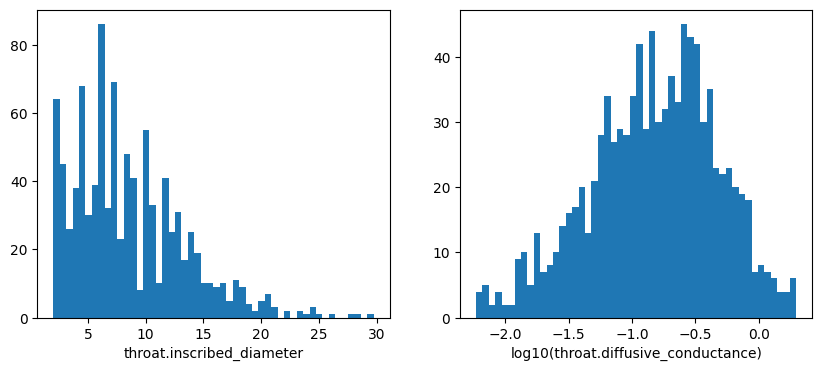

Throats with diameter < 1.5 voxels: 0
Percentiles of throat diameter: [ 2.          2.          4.89897966  7.48331499 17.88854408 23.2289917 ]
10 lowest-conductance throats:
[[182 217]
 [217 234]
 [212 310]
 [294 359]
 [ 28  31]
 [141 160]
 [124 149]
 [ 12  15]
 [349 359]
 [ 93 111]]
[0.00587531 0.00605662 0.00653148 0.00659389 0.0067206  0.00697488
 0.00709034 0.00719794 0.00730055 0.00779728]
[2.82842708 2.         3.46410155 4.         6.3245554  2.
 4.47213602 2.82842708 4.         3.46410155]
Mean coordination number: 3.336769759450172
0.0043778323718446505 0.004173569827323219 0.005811138306081254


In [67]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(pn['throat.inscribed_diameter'], bins=50)
axes[0].set_xlabel('throat.inscribed_diameter')
axes[1].hist(np.log10(phase['throat.diffusive_conductance']), bins=50)
axes[1].set_xlabel('log10(throat.diffusive_conductance)')
plt.show()

print("Throats with diameter < 1.5 voxels:", (pn['throat.inscribed_diameter'] < 1.5).sum())
print("Percentiles of throat diameter:", np.percentile(pn['throat.inscribed_diameter'], [1, 5, 25, 50, 95, 99]))
g = phase['throat.diffusive_conductance']
order = np.argsort(g)
print("10 lowest-conductance throats:")
print(pn['throat.conns'][order[:10]])
print(g[order[:10]])
print(pn['throat.inscribed_diameter'][order[:10]])
Z = 2 * pn.num_throats() / pn.num_pores()
print("Mean coordination number:", Z)
def run_direction(pn, phase, axis_labels, Lx, A):
    fd = op.algorithms.FickianDiffusion(network=pn, phase=phase)
    fd.set_value_BC(pores=pn.pores(axis_labels[0]), values=1.0)
    fd.set_value_BC(pores=pn.pores(axis_labels[1]), values=0.0)
    fd.run()
    rate = fd.rate(pores=pn.pores(axis_labels[0]))[0]
    D_eff = rate * Lx / A
    return D_eff

Dx = run_direction(pn, phase, ('xmin','xmax'), im.shape[0], im.shape[1]*im.shape[2])
Dy = run_direction(pn, phase, ('ymin','ymax'), im.shape[1], im.shape[0]*im.shape[2])
Dz = run_direction(pn, phase, ('zmin','zmax'), im.shape[2], im.shape[0]*im.shape[1])
print(Dx, Dy, Dz)